In [13]:
import pandas as pd
import matplotlib.pyplot as plt

In [14]:
prices = pd.read_csv("../data/raw/prices_raw.csv", parse_dates=True, index_col=0)
prices = prices.sort_index()
prices.head()

,HDFCBANK.NS,ITC.NS,RELIANCE.NS,SUNPHARMA.NS,TCS.NS,^NSEI
Date,,,,,,
2020-01-01,595.677124,168.796631,672.216125,405.012512,1831.109985,12182.500000
2020-01-02,599.474182,170.037262,683.660217,405.618683,1822.704590,12282.200195
2020-01-03,590.925232,169.080185,684.484009,414.617920,1859.029297,12226.650391
2020-01-06,578.136780,166.669846,668.609314,410.281525,1858.859863,11993.049805
2020-01-07,587.291382,166.847061,678.895569,416.296600,1863.421753,12052.950195


In [15]:
prices.info()
print(prices.describe())
print(prices.isna().sum())
print("Duplicate dates:", prices.index.duplicated().sum())

<class 'pandas.DataFrame'>
DatetimeIndex: 1238 entries, 2020-01-01 to 2024-12-31
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   HDFCBANK.NS   1238 non-null   float64
 1   ITC.NS        1238 non-null   float64
 2   RELIANCE.NS   1238 non-null   float64
 3   SUNPHARMA.NS  1238 non-null   float64
 4   TCS.NS        1238 non-null   float64
 5   ^NSEI         1237 non-null   float64
dtypes: float64(6)
memory usage: 67.7 KB
       HDFCBANK.NS       ITC.NS  RELIANCE.NS  SUNPHARMA.NS       TCS.NS  \
count  1238.000000  1238.000000  1238.000000   1238.000000  1238.000000   
mean    692.437057   260.404439  1095.098187    925.007410  2932.493993   
std     105.277913   108.355378   230.477783    407.397980   635.381785   
min     357.657898   104.390175   393.662384    304.801697  1395.590942   
25%     653.545090   161.380226   951.000793    594.276123  2682.970032   
50%     708.684692   226.065689  1115.586792    858.

In [16]:
prices = prices.ffill()
print(prices.isna().sum())
prices.to_csv("../data/processed/prices_clean.csv")

HDFCBANK.NS     0
ITC.NS          0
RELIANCE.NS     0
SUNPHARMA.NS    0
TCS.NS          0
^NSEI           0
dtype: int64


In [17]:
normalized = prices / prices.iloc[0] * 100
normalized.head()

,HDFCBANK.NS,ITC.NS,RELIANCE.NS,SUNPHARMA.NS,TCS.NS,^NSEI
Date,,,,,,
2020-01-01,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
2020-01-02,100.637436,100.734986,101.702442,100.149667,99.540967,100.818389
2020-01-03,99.202271,100.167986,101.824991,102.371632,101.524721,100.362408
2020-01-06,97.055394,98.740031,99.463445,101.300951,101.515468,98.444899
2020-01-07,98.592234,98.845019,100.993645,102.786109,101.764600,98.936591


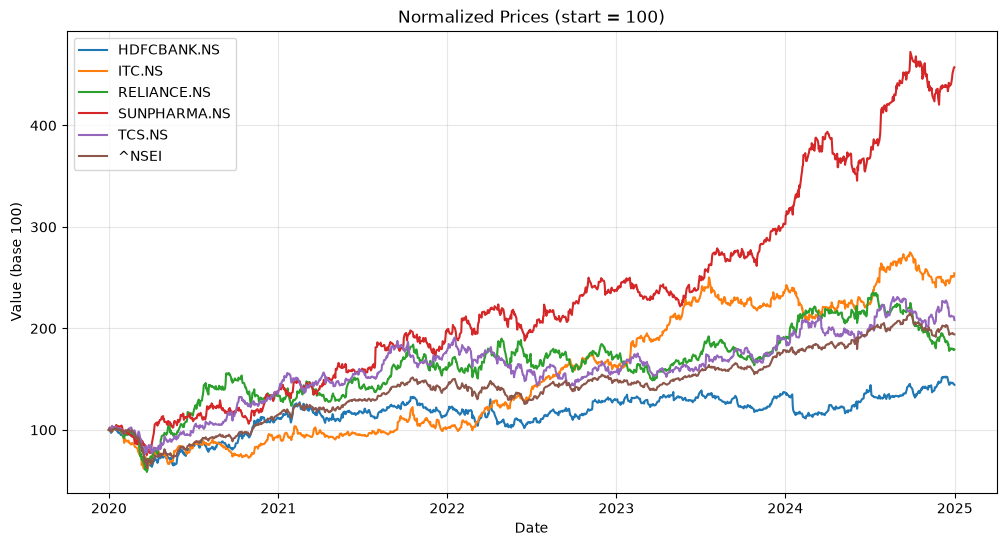

In [18]:
plt.figure(figsize=(12, 6))
for col in normalized.columns:
    plt.plot(normalized.index, normalized[col], label=col)
plt.title("Normalized Prices (start = 100)")
plt.xlabel("Date")
plt.ylabel("Value (base 100)")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("../reports/figures/normalized_prices.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

In [19]:
print("Final values:")
print(normalized.iloc[-1].sort_values(ascending=False))

march = prices.loc["2020-02-15":"2020-03-31"]
print("\nChange from 15 Feb to 31 Mar 2020 (%):")
print(((march.iloc[-1] / march.iloc[0] - 1) * 100).sort_values())

Final values:
SUNPHARMA.NS    457.265453
ITC.NS          254.298508
TCS.NS          208.267030
^NSEI           194.088248
RELIANCE.NS     179.264253
HDFCBANK.NS     144.436110
Name: 2024-12-31 00:00:00, dtype: float64

Change from 15 Feb to 31 Mar 2020 (%):
HDFCBANK.NS    -29.187042
^NSEI          -28.624499
RELIANCE.NS    -24.657520
TCS.NS         -16.512346
ITC.NS         -16.162098
SUNPHARMA.NS   -13.736530
dtype: float64
